# HW2 — Unsupervised learning on music metadata

We use PCA, t-SNE, K-Means, Silhouette score, and Adjusted Rand Index on the filtered FMA dataset.

## Student information

- **Name:** Oleg Yurchik
- **Group:** J4133
- **Assignment:** HW2



In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.feature_selection import f_classif

DATA = Path('./fma_dataset_filtered.csv')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
df = pd.read_csv(DATA)

## 1. Preprocessing

`genre` is retained only as an external reference for coloured visualizations and ARI. It is never used as an input feature for PCA or K-Means.

In [2]:
genre = df['genre'].astype(str)
feature_columns = df.select_dtypes(include=np.number).columns.drop('track_id', errors='ignore')
X_raw = df[feature_columns].replace([np.inf, -np.inf], np.nan)
X_imputed = SimpleImputer(strategy='median').fit_transform(X_raw)
constant = np.nanstd(X_imputed, axis=0) == 0
X_imputed = X_imputed[:, ~constant]
feature_columns = feature_columns[~constant]
X = StandardScaler().fit_transform(X_imputed)
preprocessing_summary = pd.DataFrame({
    'quantity': ['rows', 'numeric features before filtering', 'features after filtering', 'genres'],
    'value': [len(df), len(feature_columns) + int(constant.sum()), X.shape[1], genre.nunique()]
}).set_index('quantity')
preprocessing_summary

,value
quantity,
rows,2406
numeric features before filtering,522
features after filtering,518
genres,4


## 2. PCA and t-SNE visualization

t-SNE is computed on a reproducible sample after a 50-dimensional PCA pre-reduction. This keeps the visualization practical while preserving the main structure of the data.

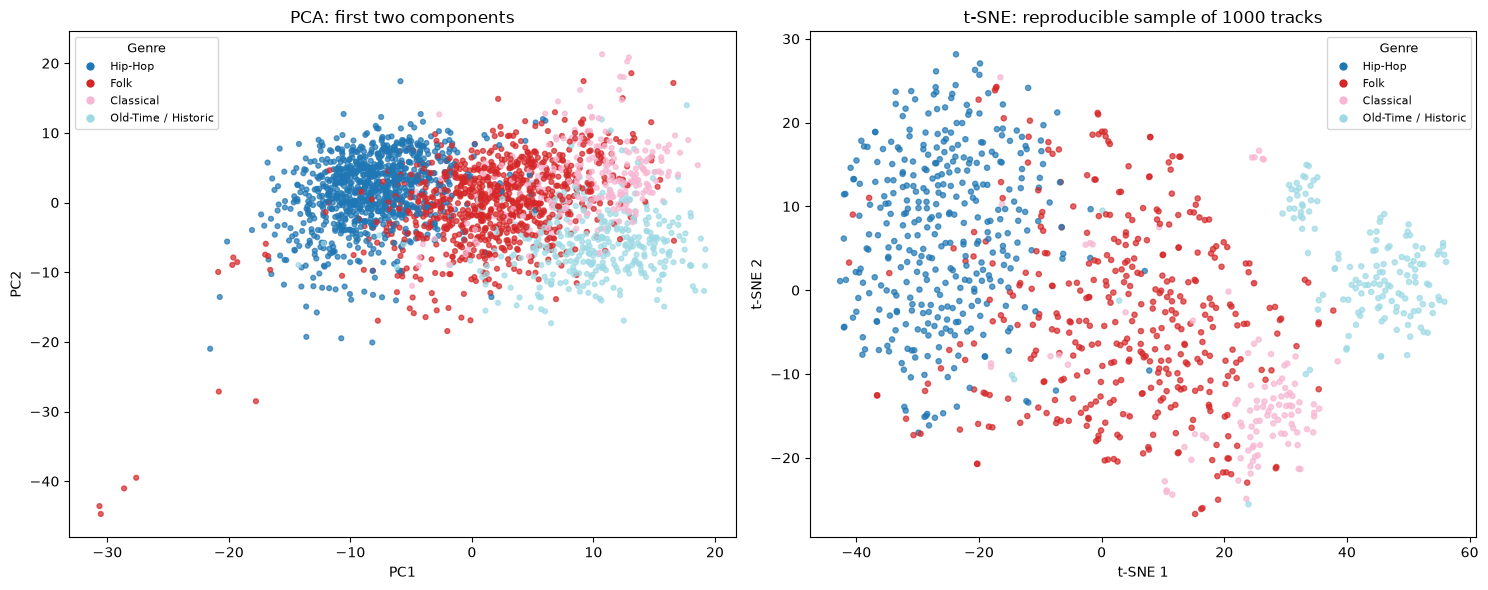

In [3]:
pca_full = PCA().fit(X)
explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)
pca_2 = PCA(n_components=2, random_state=42).fit_transform(X)

rng = np.random.default_rng(42)
sample_size = min(1000, len(X))
sample_idx = rng.choice(len(X), sample_size, replace=False)
X_50 = PCA(n_components=min(50, X.shape[1]), random_state=42).fit_transform(X)
tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=42).fit_transform(X_50[sample_idx])

genre_labels = pd.unique(genre); genre_codes = pd.Categorical(genre, categories=genre_labels).codes; fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(pca_2[:, 0], pca_2[:, 1], c=genre_codes, cmap='tab20', s=12, alpha=.7)
axes[0].set(title='PCA: first two components', xlabel='PC1', ylabel='PC2')
axes[1].scatter(tsne[:, 0], tsne[:, 1], c=genre_codes[sample_idx], cmap='tab20', s=14, alpha=.7)
axes[1].set(title=f't-SNE: reproducible sample of {sample_size} tracks', xlabel='t-SNE 1', ylabel='t-SNE 2')
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.cm.tab20(i / max(1, len(genre_labels) - 1)), markersize=7, label=str(label)) for i, label in enumerate(genre_labels)]; [ax.legend(handles=handles, title='Genre', fontsize=8, title_fontsize=9) for ax in axes]; plt.tight_layout(); plt.show()
fig.savefig(OUT / 'pca_tsne_genres.png', dpi=160, bbox_inches='tight')

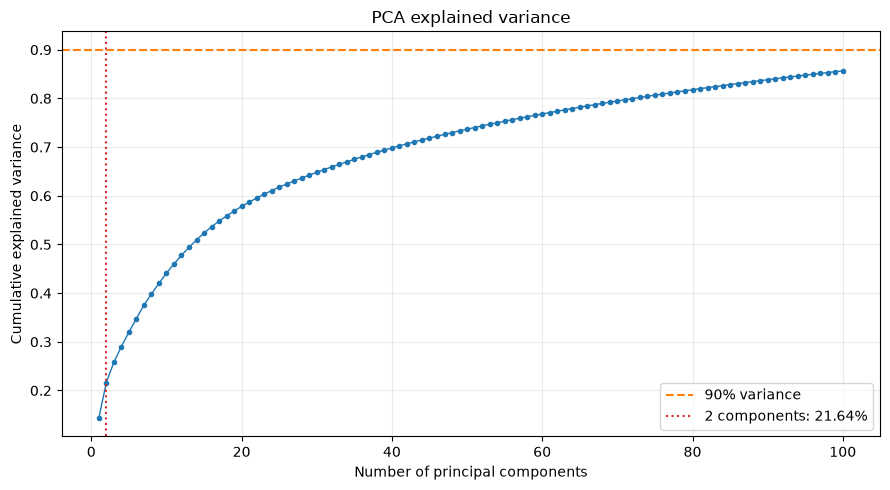

,components,explained_variance
0,2,0.216410
1,130,0.900118


In [4]:
components = np.arange(1, min(100, len(explained)) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(components, cum_explained[:len(components)], marker='.', linewidth=1)
ax.axhline(.90, color='tab:orange', linestyle='--', label='90% variance')
ax.axvline(2, color='tab:red', linestyle=':', label=f'2 components: {cum_explained[1]:.2%}')
ax.set(xlabel='Number of principal components', ylabel='Cumulative explained variance', title='PCA explained variance')
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()
fig.savefig(OUT / 'pca_explained_variance.png', dpi=160, bbox_inches='tight')
variance_summary = pd.DataFrame({'components': [2, int(np.argmax(cum_explained >= .90) + 1)], 'explained_variance': [cum_explained[1], cum_explained[np.argmax(cum_explained >= .90)]]})
variance_summary

## 3. K-Means model selection

For each number of clusters from 2 to 6, we report the internal Silhouette score and external Adjusted Rand Index. The latter uses genre labels only for evaluation.

In [5]:
cluster_rows = []
labels_by_k = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(X)
    labels_by_k[k] = labels
    cluster_rows.append({
        'k': k,
        'silhouette': silhouette_score(X, labels),
        'adjusted_rand_index': adjusted_rand_score(genre, labels),
    })
cluster_scores = pd.DataFrame(cluster_rows).set_index('k')
cluster_scores.round(4)

,silhouette,adjusted_rand_index
k,,
2,0.1096,0.3605
3,0.0899,0.5271
4,0.0753,0.4533
5,0.0718,0.5071
6,0.0721,0.5062


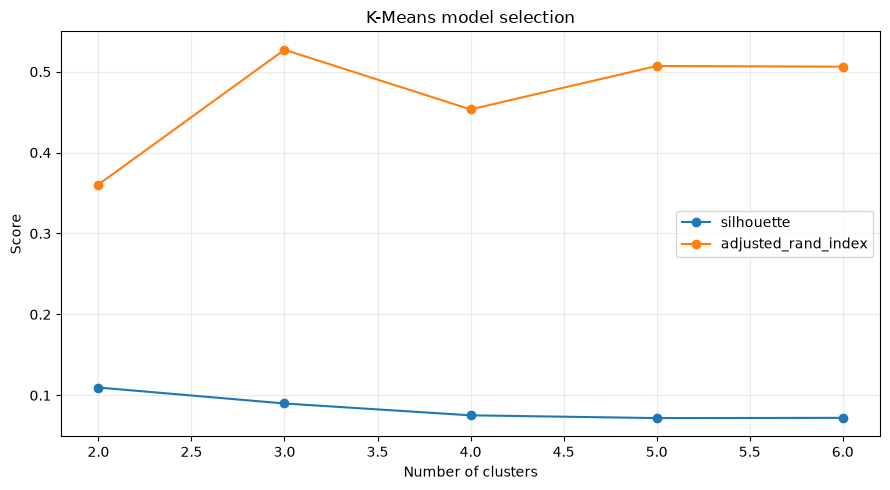

,best_k,best_score
criterion,,
Silhouette,2,0.1096
Adjusted Rand Index,3,0.5271


In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
cluster_scores.plot(marker='o', ax=ax)
ax.set(title='K-Means model selection', xlabel='Number of clusters', ylabel='Score')
ax.grid(alpha=.25); plt.tight_layout(); plt.show()
fig.savefig(OUT / 'kmeans_model_selection.png', dpi=160, bbox_inches='tight')
best_silhouette_k = int(cluster_scores['silhouette'].idxmax())
best_ari_k = int(cluster_scores['adjusted_rand_index'].idxmax())
selection_summary = pd.DataFrame({
    'criterion': ['Silhouette', 'Adjusted Rand Index'],
    'best_k': [best_silhouette_k, best_ari_k],
    'best_score': [cluster_scores.loc[best_silhouette_k, 'silhouette'], cluster_scores.loc[best_ari_k, 'adjusted_rand_index']]
}).set_index('criterion')
selection_summary.round(4)

## 4. Answers to the questions

### 4.1 Does the visualization reflect the real genre distribution?

PCA preserves global linear variance, while t-SNE emphasizes local neighbourhoods and can create visually separated islands. Therefore, apparent visual separation is not by itself proof that genres are well separated. The comparison of ARI and the plots gives the evidence for this dataset.

### 4.2 How much variance remains in two components?

The exact value is shown in `variance_summary` and marked on the explained-variance plot.

### 4.3 Silhouette or Rand Index?

Silhouette is appropriate when no labels are available because it measures compactness and separation. ARI can be more informative here only because genre labels are available, but it would not be usable in the real unsupervised setting.

### 4.4 Recommendation system without genres

Scale the audio features, reduce dimensionality with PCA, and recommend tracks by nearest-neighbour search in the reduced space. Cosine distance is a good starting point; the number of neighbours can be tuned using user feedback.

### 4.5 Most important feature

The following exploratory table ranks features by one-way ANOVA association with genre. This is not used to train K-Means and should be interpreted as a diagnostic, not causal importance.

In [7]:
f_values, p_values = f_classif(X, genre)
feature_diagnostics = pd.DataFrame({'feature': feature_columns, 'anova_f': f_values, 'p_value': p_values}).sort_values('anova_f', ascending=False).head(15)
feature_diagnostics

,feature,anova_f,p_value
271,mfcc_max_04,1920.277953,0.0
291,mfcc_mean_04,1905.682425,0.0
311,mfcc_median_04,1822.680686,0.0
315,mfcc_median_08,1265.308091,0.0
295,mfcc_mean_08,1261.594775,0.0
273,mfcc_max_06,1205.988345,0.0
293,mfcc_mean_06,1085.261679,0.0
313,mfcc_median_06,1047.168281,0.0
275,mfcc_max_08,1044.618916,0.0
422,spectral_contrast_max_07,1011.743028,0.0


## Conclusion

PCA is useful for compact visualization and for measuring how much variance is preserved by a low-dimensional representation. t-SNE reveals local neighborhood structure, but its coordinates should not be interpreted as global distances. K-Means results depend on the chosen number of clusters: Silhouette score evaluates geometric separation, while Adjusted Rand Index compares the clustering with the external genre labels. Since genre is used only for evaluation and visualization, not as an input feature, the clustering remains unsupervised. Overall, the analysis demonstrates that different quality criteria can select different values of `k`, so the choice should be justified by both metrics and the practical interpretation of the clusters.
